In [1]:
pip install nltk textblob wordcloud

  Using cached regex-2026.9.29-cp312-cp312-win_amd64.whl.metadata (41 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 2.1 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 2.4 MB/s eta 0:00:01
   ------------------------------------ --- 1.6/1.7 MB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.2 MB/s  0:00:00
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   --------------------------------- ------ 524.3/625.0 kB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 625.0/625.0 kB 1.9 MB/s  0:00:00
Using cached regex-2026.9.29-cp312-cp312-win_amd64.whl (280 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/5 [tqdm]
   -------------------------

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from textblob import TextBlob
from wordcloud import WordCloud
from collections import Counter

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 6)

In [5]:
df = pd.read_csv("../data/sentimentdataset.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset Shape: (732, 15)

Columns:
['Unnamed: 0.1', 'Unnamed: 0', 'Text', 'Sentiment', 'Timestamp', 'User', 'Platform', 'Hashtags', 'Retweets', 'Likes', 'Country', 'Year', 'Month', 'Day', 'Hour']


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [6]:
print("Dataset Shape:", df.shape)
print(df.columns.tolist())

Dataset Shape: (732, 15)
['Unnamed: 0.1', 'Unnamed: 0', 'Text', 'Sentiment', 'Timestamp', 'User', 'Platform', 'Hashtags', 'Retweets', 'Likes', 'Country', 'Year', 'Month', 'Day', 'Hour']


In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nSentiment Distribution in Original Dataset:")
print(df["Sentiment"].value_counts())

print("\nPlatforms:")
print(df["Platform"].value_counts())

print("\nCountries:")
print(df["Country"].value_counts().head(10))

Missing Values:
Unnamed: 0.1    0
Unnamed: 0      0
Text            0
Sentiment       0
Timestamp       0
User            0
Platform        0
Hashtags        0
Retweets        0
Likes           0
Country         0
Year            0
Month           0
Day             0
Hour            0
dtype: int64

Duplicate Rows: 0

Sentiment Distribution in Original Dataset:
Sentiment
Positive         44
Joy              42
Excitement       32
Contentment      14
Neutral          14
                 ..
Boredom           1
Indifference      1
Disgust           1
Relief            1
Positive          1
Name: count, Length: 279, dtype: int64

Platforms:
Platform
Instagram     258
Facebook      231
Twitter       128
Twitter       115
Name: count, dtype: int64

Countries:
Country
USA               59
USA               55
UK                49
Canada            44
Australia         41
Canada            34
UK                33
India             21
USA               20
Canada            17
Name: count, dtype:

In [8]:
df[["Text", "Sentiment", "Platform", "Timestamp"]].head(10)

,Text,Sentiment,Platform,Timestamp
0,Enjoying a beautiful day at the park! ...,Positive,Twitter,2023-01-15 12:30:00
1,Traffic was terrible this morning. ...,Negative,Twitter,2023-01-15 08:45:00
2,Just finished an amazing workout! 💪 ...,Positive,Instagram,2023-01-15 15:45:00
3,Excited about the upcoming weekend getaway! ...,Positive,Facebook,2023-01-15 18:20:00
4,Trying out a new recipe for dinner tonight. ...,Neutral,Instagram,2023-01-15 19:55:00
5,Feeling grateful for the little things in lif...,Positive,Twitter,2023-01-16 09:10:00
6,Rainy days call for cozy blankets and hot coc...,Positive,Facebook,2023-01-16 14:45:00
7,The new movie release is a must-watch! ...,Positive,Instagram,2023-01-16 19:30:00
8,Political discussions heating up on the timel...,Negative,Twitter,2023-01-17 08:00:00
9,Missing summer vibes and beach days. ...,Neutral,Facebook,2023-01-17 12:20:00


In [9]:
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"], errors="ignore")

In [10]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (712, 13)


In [11]:
print(df.isnull().sum())

Text         0
Sentiment    0
Timestamp    0
User         0
Platform     0
Hashtags     0
Retweets     0
Likes        0
Country      0
Year         0
Month        0
Day          0
Hour         0
dtype: int64


In [12]:
df = df.dropna(subset=["Text"]).reset_index(drop=True)

print("Final dataset shape:", df.shape)

Final dataset shape: (712, 13)


In [13]:
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tuntun'\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [14]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = str(text).lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    
    # Remove mentions
    text = re.sub(r"@\w+", "", text)
    
    # Remove hashtag symbol but keep the word
    text = re.sub(r"#", "", text)
    
    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    
    # Remove stop words
    words = text.split()
    words = [word for word in words if word not in stop_words]
    
    return " ".join(words)

In [15]:
df["Cleaned_Text"] = df["Text"].apply(clean_text)

df[["Text", "Cleaned_Text"]].head(10)

,Text,Cleaned_Text
0,Enjoying a beautiful day at the park! ...,enjoying beautiful day park
1,Traffic was terrible this morning. ...,traffic terrible morning
2,Just finished an amazing workout! 💪 ...,finished amazing workout
3,Excited about the upcoming weekend getaway! ...,excited upcoming weekend getaway
4,Trying out a new recipe for dinner tonight. ...,trying new recipe dinner tonight
5,Feeling grateful for the little things in lif...,feeling grateful little things life
6,Rainy days call for cozy blankets and hot coc...,rainy days call cozy blankets hot cocoa
7,The new movie release is a must-watch! ...,new movie release mustwatch
8,Political discussions heating up on the timel...,political discussions heating timeline
9,Missing summer vibes and beach days. ...,missing summer vibes beach days


In [16]:
def get_polarity(text):
    return TextBlob(text).sentiment.polarity

df["Polarity"] = df["Cleaned_Text"].apply(get_polarity)

df[["Cleaned_Text", "Polarity"]].head(10)

,Cleaned_Text,Polarity
0,enjoying beautiful day park,0.675000
1,traffic terrible morning,-1.000000
2,finished amazing workout,0.600000
3,excited upcoming weekend getaway,0.375000
4,trying new recipe dinner tonight,0.136364
5,feeling grateful little things life,-0.187500
6,rainy days call cozy blankets hot cocoa,0.025000
7,new movie release mustwatch,0.136364
8,political discussions heating timeline,0.000000
9,missing summer vibes beach days,-0.200000


In [17]:
def classify_sentiment(polarity):
    if polarity > 0.05:
        return "Positive"
    elif polarity < -0.05:
        return "Negative"
    else:
        return "Neutral"

df["Predicted_Sentiment"] = df["Polarity"].apply(classify_sentiment)

print(df["Predicted_Sentiment"].value_counts())

Predicted_Sentiment
Neutral     340
Positive    260
Negative    112
Name: count, dtype: int64


In [18]:
comparison = pd.crosstab(
    df["Sentiment"],
    df["Predicted_Sentiment"]
)

print(comparison)

Predicted_Sentiment  Negative  Neutral  Positive
Sentiment                                       
Acceptance                  0        3         0
Acceptance                  1        3         1
Accomplishment              0        0         3
Admiration                  0        0         1
Admiration                  0        1         1
...                       ...      ...       ...
Wonder                      0        1         0
Wonder                      0        1         0
Wonderment                  0        1         0
Yearning                    1        1         0
Zest                        0        0         2

[279 rows x 3 columns]


In [19]:
agreement = (
    df["Sentiment"].astype(str).str.lower()
    == df["Predicted_Sentiment"].astype(str).str.lower()
).mean()

print(f"Sentiment Agreement: {agreement:.2%}")

Sentiment Agreement: 0.00%


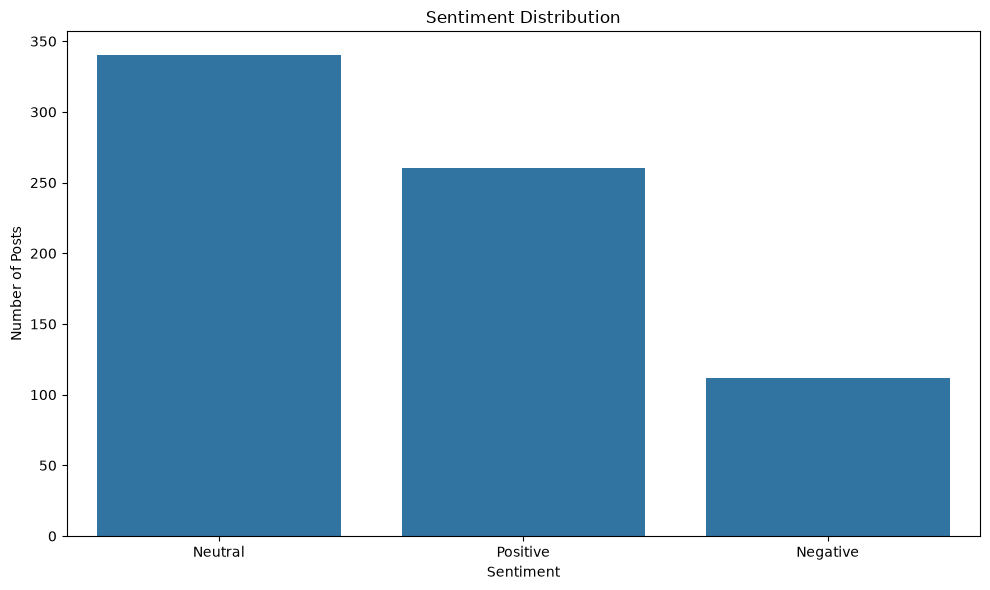

In [20]:
sentiment_counts = df["Predicted_Sentiment"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")
plt.tight_layout()

plt.savefig(
    "../visuals/sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

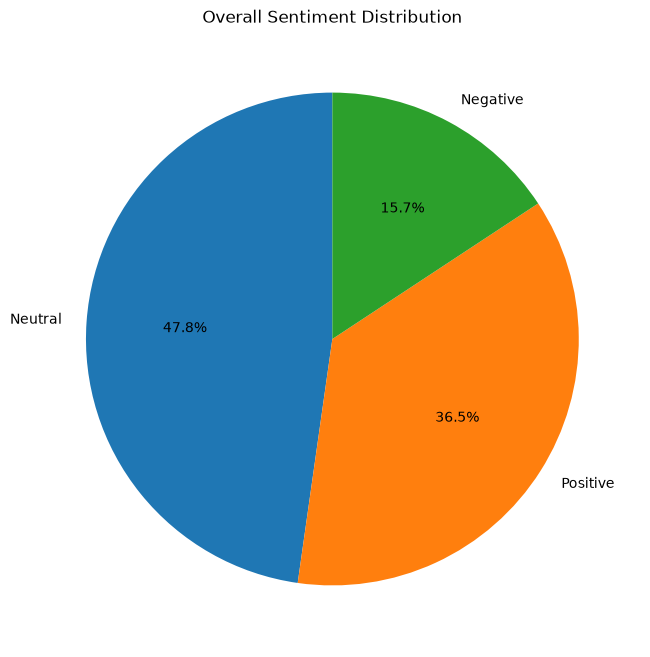

In [21]:
plt.figure(figsize=(8, 8))

plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Overall Sentiment Distribution")

plt.savefig(
    "../visuals/sentiment_pie_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

print(df["Timestamp"].isna().sum())

0


In [23]:
df["Month_Date"] = df["Timestamp"].dt.to_period("M").astype(str)

sentiment_over_time = (
    df.groupby(["Month_Date", "Predicted_Sentiment"])
      .size()
      .unstack(fill_value=0)
)

sentiment_over_time

Predicted_Sentiment,Negative,Neutral,Positive
Month_Date,,,
2010-05,0,0,1
2010-08,0,1,0
2010-11,0,0,1
2011-06,0,1,0
2011-07,0,1,0
...,...,...,...
2023-06,5,10,16
2023-07,2,12,7
2023-08,5,11,15


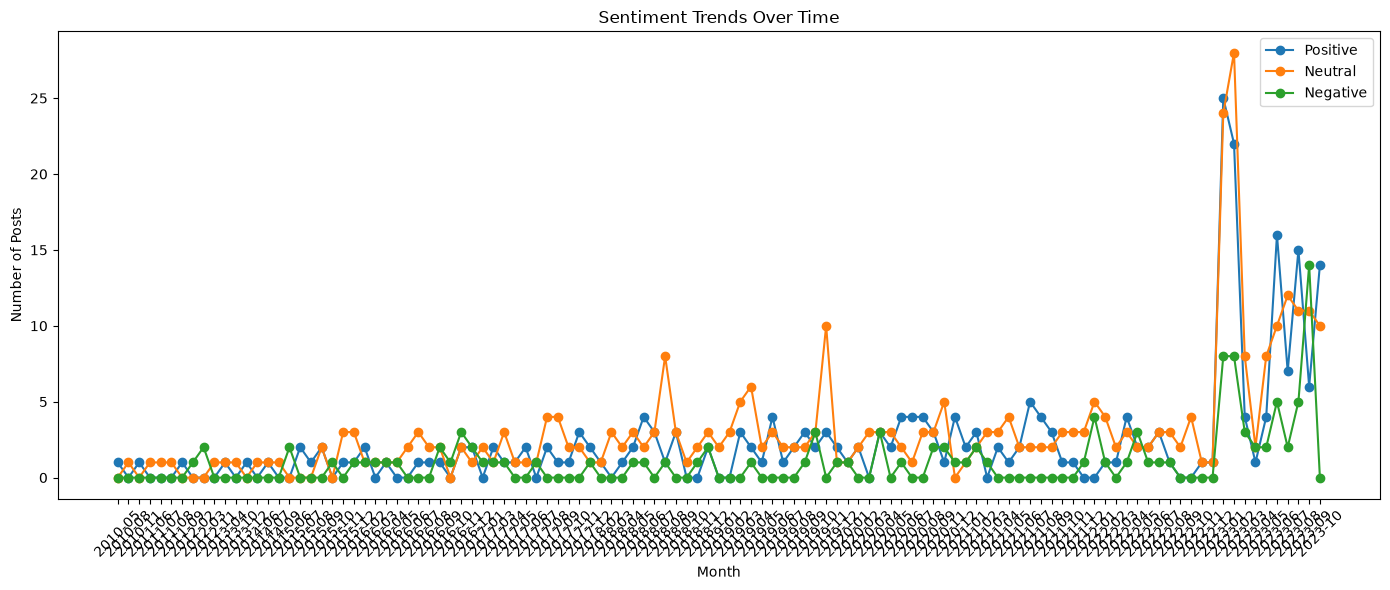

In [24]:
plt.figure(figsize=(14, 6))

for sentiment in ["Positive", "Neutral", "Negative"]:
    if sentiment in sentiment_over_time.columns:
        plt.plot(
            sentiment_over_time.index,
            sentiment_over_time[sentiment],
            marker="o",
            label=sentiment
        )

plt.title("Sentiment Trends Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../visuals/sentiment_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
platform_sentiment = pd.crosstab(
    df["Platform"],
    df["Predicted_Sentiment"]
)

platform_sentiment

Predicted_Sentiment,Negative,Neutral,Positive
Platform,,,
Facebook,35,117,72
Instagram,32,114,106
Twitter,22,55,45
Twitter,23,54,37


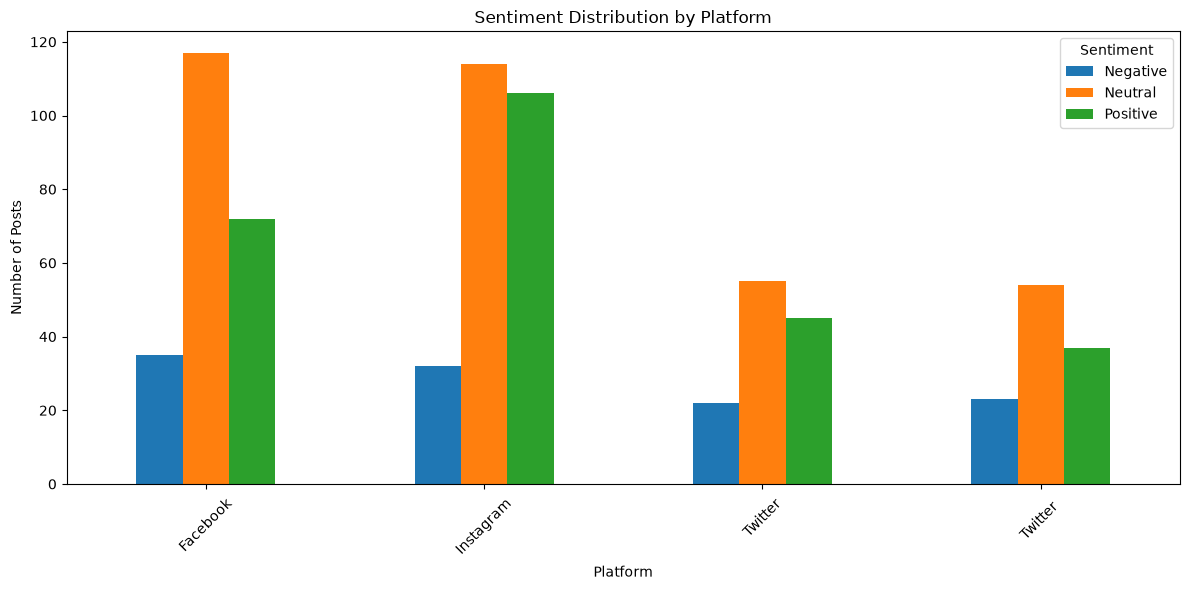

In [26]:
platform_sentiment.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Sentiment Distribution by Platform")
plt.xlabel("Platform")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()

plt.savefig(
    "../visuals/sentiment_by_platform.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

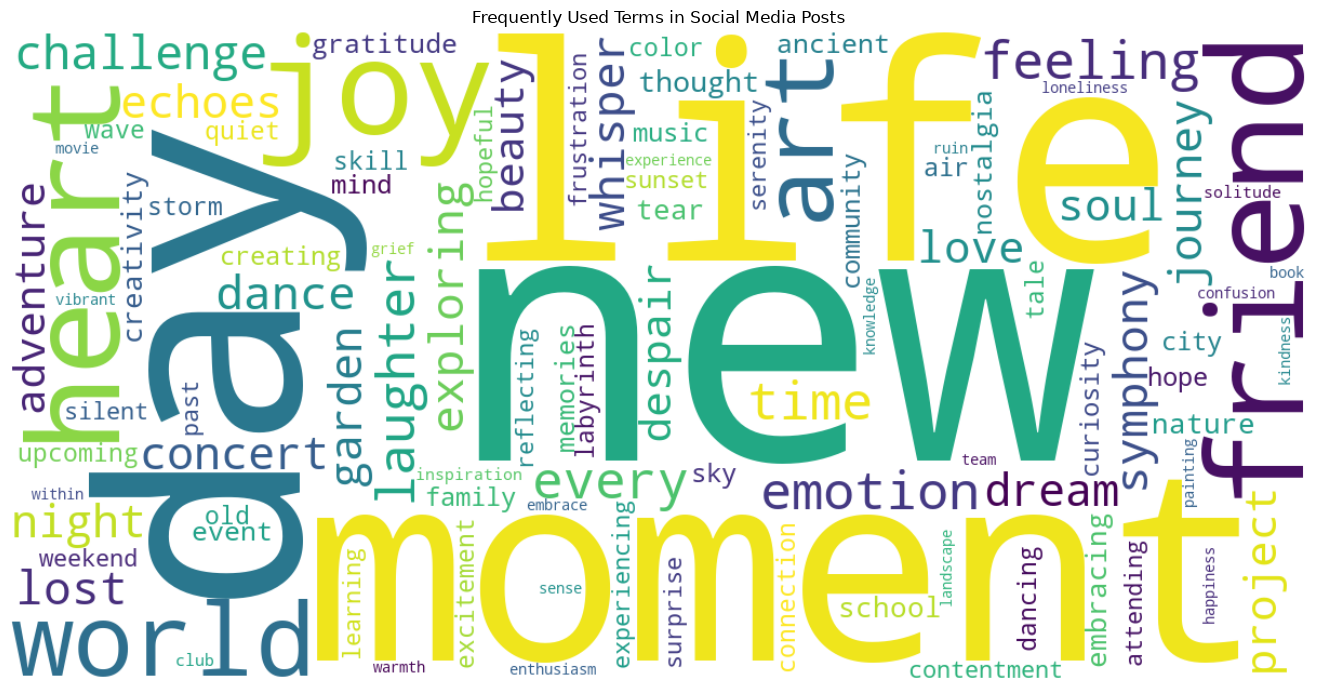

In [27]:
all_text = " ".join(df["Cleaned_Text"].dropna())

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(all_text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Frequently Used Terms in Social Media Posts")
plt.tight_layout()

plt.savefig(
    "../visuals/wordcloud.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

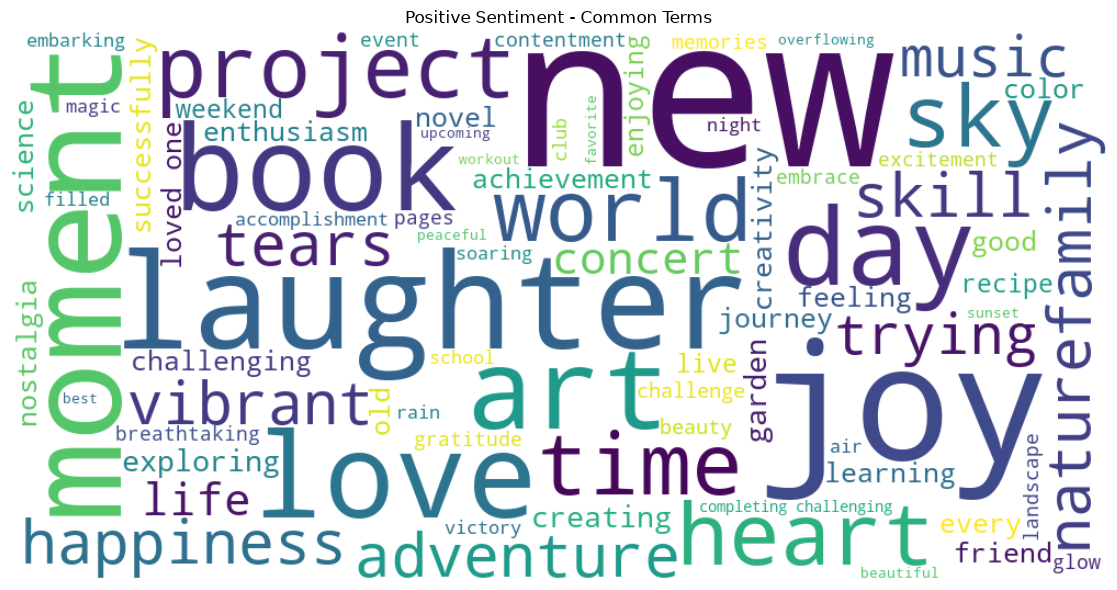

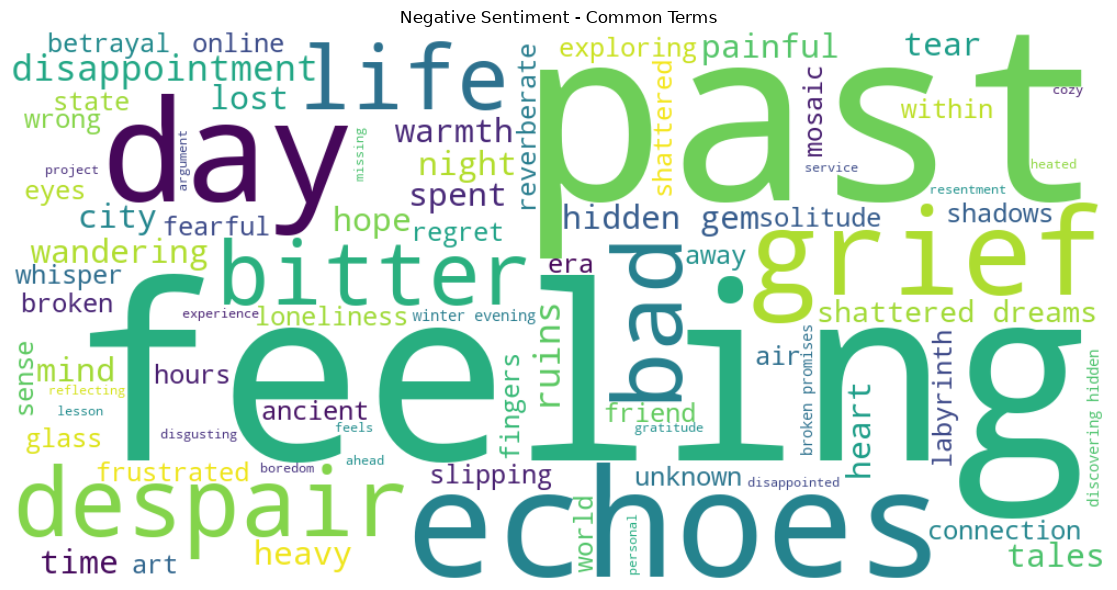

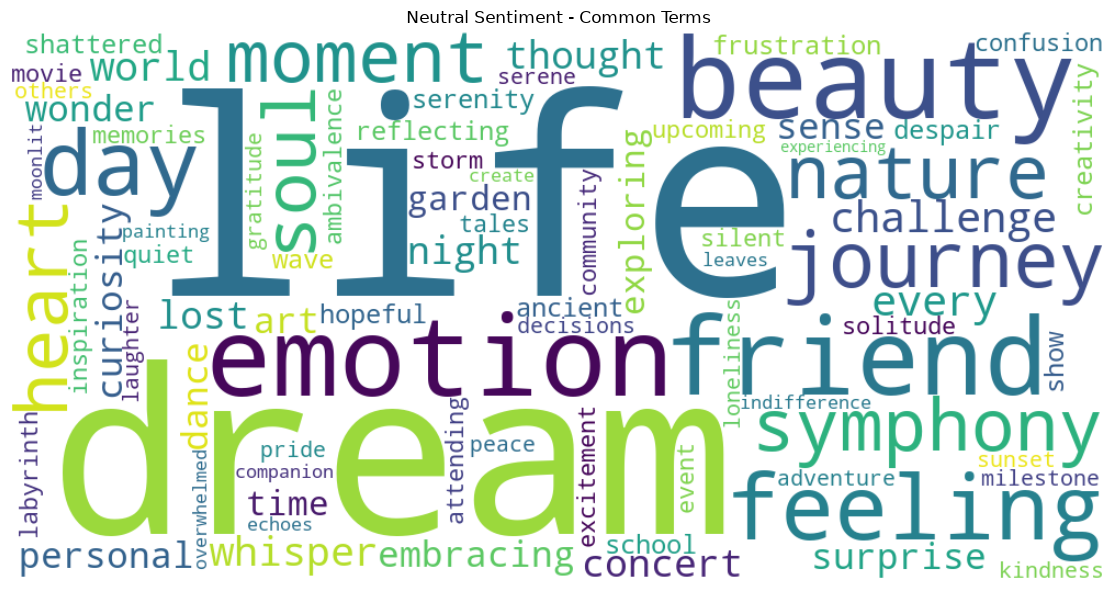

In [28]:
for sentiment in ["Positive", "Negative", "Neutral"]:
    
    text = " ".join(
        df.loc[
            df["Predicted_Sentiment"] == sentiment,
            "Cleaned_Text"
        ].dropna()
    )
    
    if text.strip():
        wc = WordCloud(
            width=1000,
            height=500,
            background_color="white",
            max_words=80
        ).generate(text)
        
        plt.figure(figsize=(12, 6))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"{sentiment} Sentiment - Common Terms")
        plt.tight_layout()
        plt.show()

In [29]:
engagement_summary = (
    df.groupby("Predicted_Sentiment")[["Likes", "Retweets"]]
      .mean()
      .round(2)
)

engagement_summary

,Likes,Retweets
Predicted_Sentiment,,
Negative,37.00,18.58
Neutral,42.09,21.11
Positive,46.68,23.39


In [30]:
df["Total_Engagement"] = df["Likes"] + df["Retweets"]

engagement_by_sentiment = (
    df.groupby("Predicted_Sentiment")["Total_Engagement"]
      .mean()
      .sort_values(ascending=False)
      .round(2)
)

print(engagement_by_sentiment)

Predicted_Sentiment
Positive    70.07
Neutral     63.20
Negative    55.58
Name: Total_Engagement, dtype: float64


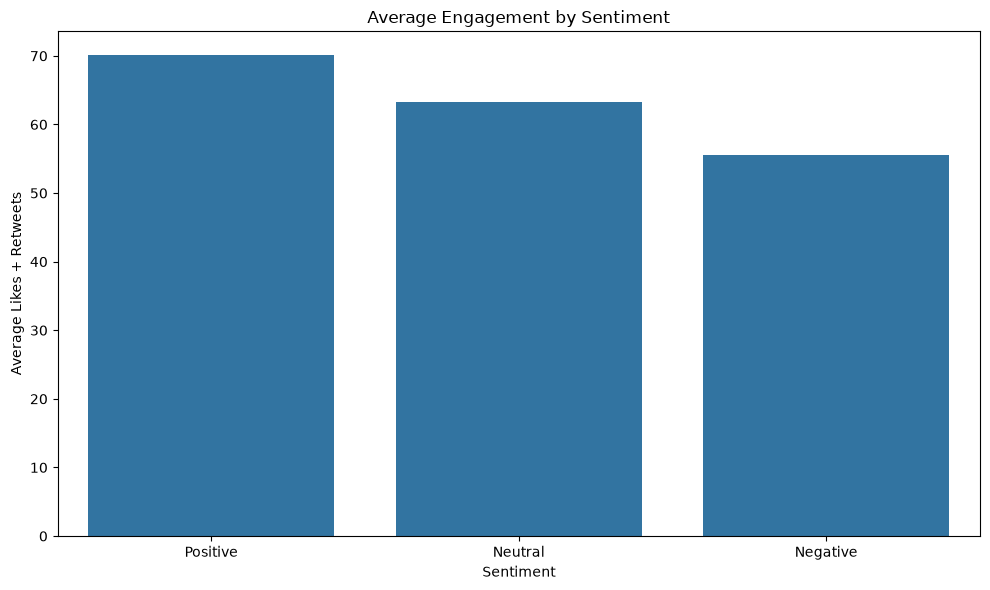

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=engagement_by_sentiment.index,
    y=engagement_by_sentiment.values
)

plt.title("Average Engagement by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Likes + Retweets")
plt.tight_layout()

plt.show()

In [32]:
print(
    df.nlargest(5, "Polarity")[
        ["Text", "Polarity", "Platform"]
    ].to_string(index=False)
)

                                                                                                       Text  Polarity    Platform
                                                     Laughter is the best medicine—enjoying a comedy show.        1.0   Facebook 
                                                   Experiencing awe at the breathtaking sunset.                   1.0   Facebook 
                                           Awe-struck by the breathtaking sunrise over the mountains.             1.0  Instagram 
At the summit of Machu Picchu, a breathtaking panorama that whispers the secrets of ancient civilizations.        1.0   Facebook 
      At the summit of Mount Fuji, a breathtaking sunrise that paints the sky with hues of accomplishment.        1.0   Facebook 


In [33]:
print(
    df.nsmallest(5, "Polarity")[
        ["Text", "Polarity", "Platform"]
    ].to_string(index=False)
)

                                                                                                                                  Text  Polarity   Platform
                                                                                   Traffic was terrible this morning.                       -1.0  Twitter  
                                                                             The state of the world's environment is just disgusting.       -1.0  Twitter  
                                                                        The state of corruption in our society is utterly disgusting.       -1.0  Twitter  
 Fearful eyes scanning the shadows, a prisoner of the night, terrorized by the lurking monsters born from the mind's darkest corners.       -0.9   Twitter 
                                                                                   Grief overwhelms, a storm of emotions within.            -0.8  Twitter  


In [34]:
print("===== SOCIAL MEDIA SENTIMENT SUMMARY =====")

print("\nTotal Posts:", len(df))

print("\nSentiment Distribution:")
print(df["Predicted_Sentiment"].value_counts())

print("\nAverage Polarity:")
print(round(df["Polarity"].mean(), 3))

print("\nPlatform Distribution:")
print(df["Platform"].value_counts())

print("\nAverage Engagement by Sentiment:")
print(engagement_by_sentiment)

===== SOCIAL MEDIA SENTIMENT SUMMARY =====

Total Posts: 712

Sentiment Distribution:
Predicted_Sentiment
Neutral     340
Positive    260
Negative    112
Name: count, dtype: int64

Average Polarity:
0.09

Platform Distribution:
Platform
Instagram     252
Facebook      224
Twitter       122
Twitter       114
Name: count, dtype: int64

Average Engagement by Sentiment:
Predicted_Sentiment
Positive    70.07
Neutral     63.20
Negative    55.58
Name: Total_Engagement, dtype: float64


In [35]:
output_path = "../data/analyzed_social_media_sentiments.csv"

df.to_csv(
    output_path,
    index=False
)

print(f"Analyzed dataset saved to: {output_path}")

Analyzed dataset saved to: ../data/analyzed_social_media_sentiments.csv
